# Practica Regresion Lineal Múltiple

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

**DISEñAMOS EL DATASET**

In [ ]:
m = 100; # cantidad de muestras
theta0_obj = 10; 
theta1_obj = 4;
theta2_obj = -2;
x_obj = np.linspace(-1, 5, num = m);

In [ ]:
x_obj.size

100

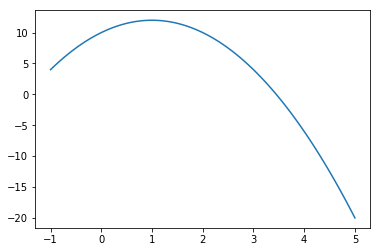

In [ ]:
y_obj = theta0_obj + theta1_obj*x_obj + theta2_obj*x_obj**2;
plt.plot(x_obj, y_obj)

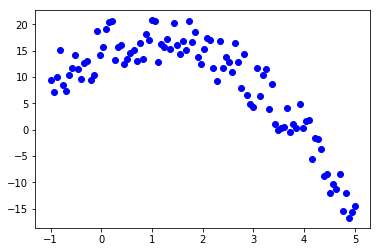

In [ ]:
ruido = 10 - 10*np.random.rand(m);
y_obj = theta0_obj + theta1_obj*x_obj + theta2_obj*x_obj**2;
plt.plot(x_obj, y_obj+(ruido), 'bo')
y_obj = y_obj+(ruido)

**GRADIENTE DESCENDENTE**

10 4 -2
13.175343002690697 8.56645207954724 -1.4694615564720657 -1.1131161005494528 0.16861117906354686
6.729233377758424 -0.06589655111274062 0.003481839782543986 0.0033190002548561777 0.0026676421441049454 -0.000589148409651216


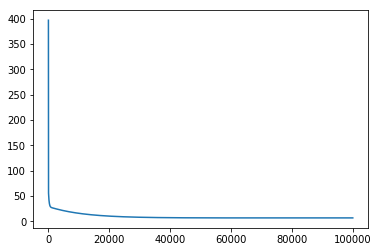

In [ ]:
max_iter = 100000
theta0 = 3
theta1 = 10
theta2 = -0.1
theta3 = 0
theta4 = 0
alpha = 0.0001 #Coeficiente de aprendizaje
J = np.zeros(max_iter)
save = [[theta0, theta1, theta2, theta3, theta4]]

x0 = 1
x1 = x_obj
x2 = x_obj**2
x3 = x_obj**3
x4 = x_obj**4

for i in range(max_iter):
    dJ0 = 0
    dJ1 = 0
    dJ2 = 0
    dJ3 = 0
    dJ4 = 0
    for j in range(m):
        h = theta0*x0 + theta1*x1[j] + theta2*x2[j] + theta3*x3[j] + theta4*x4[j]
        dJ0 = dJ0 + (1/m)*(h - y_obj[j])
        dJ1 = dJ1 + (1/m)*(h - y_obj[j])*x1[j]
        dJ2 = dJ1 + (1/m)*(h - y_obj[j])*x2[j]
        dJ3 = dJ1 + (1/m)*(h - y_obj[j])*x3[j]
        dJ4 = dJ1 + (1/m)*(h - y_obj[j])*x4[j]
        J[i]= J[i] + (1/(2*m))*(y_obj[j] - h)**2
    theta0 = theta0 - alpha*dJ0
    theta1 = theta1 - alpha*dJ1
    theta2 = theta2 - alpha*dJ2
    theta3 = theta3 - alpha*dJ3
    theta4 = theta4 - alpha*dJ4
    save.append([theta0, theta1, theta2, theta3, theta4])

print(theta0_obj, theta1_obj, theta2_obj)     
print(theta0, theta1, theta2, theta3, theta4)  
print(J[-1], dJ0, dJ1, dJ2, dJ3, dJ4)
plt.plot(range(max_iter), J) 

In [ ]:
save_reshape = np.array(save)
save_reshape = np.reshape(save_reshape, (-1, 5))
save_anim = save_reshape[0:10000:100,:]
save_anim.shape

(100, 5)

In [ ]:
from matplotlib import animation, rc

fig, ax = plt.subplots(1, 1, figsize=(10, 5))

line1, = ax.plot([], [], 'o', lw=2)
line2, = ax.plot([], [], lw=2)

ax.set_ylim(-20, 30)
ax.set_xlim(-5, 7)
plt.close()

def init():
    line1.set_data(x_obj, y_obj)
    return (line1,)    
    
def animate(i):
    x = x_obj
    y = save_anim[i,0] + save_anim[i,1]*x1 + save_anim[i,2]*x2 + save_anim[i,3]*x3 + save_anim[i,4]*x4
    line2.set_data(x, y)
    return line2,

anim = animation.FuncAnimation(fig, animate, init_func=init,
                               frames=save_anim.shape[0], interval=100, blit=True)

rc('animation', html='jshtml')
anim

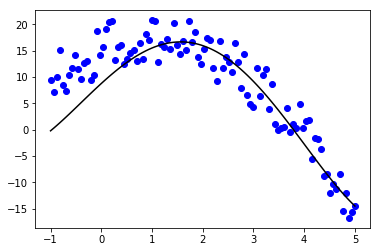

In [ ]:
plt.plot(x_obj, y_obj, 'bo')
plt.plot(x_obj, theta0 + theta1*x1 + theta2*x2 + theta3*x3 + theta4*x4, 'k')

**Predicciones**

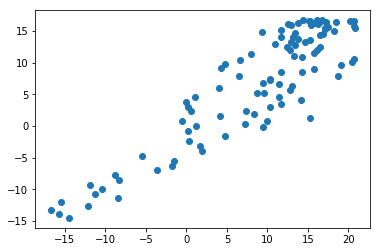

In [ ]:
predicciones = theta0 + theta1*x1 + theta2*x2 + theta3*x3 + theta4*x4
plt.scatter(y_obj,predicciones)

In [ ]:
from sklearn import metrics
print('MAE:', metrics.mean_absolute_error(y_obj,predicciones))
print('MSE:', metrics.mean_squared_error(y_obj,predicciones))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_obj,predicciones)))

MAE: 3.516675032315094
MSE: 20.47235898231687
RMSE: 4.524639099676003


# Regularización

10 4 -2
8.893573808797003 3.854876994360554e-06 -0.019374493337236755 -0.09685563206911302 -0.004848565378531223
69.34605235777244 -2.891098345076538 0.00041727227252153594 0.002401413202459235 0.012021583807232616 0.0005960913928646505


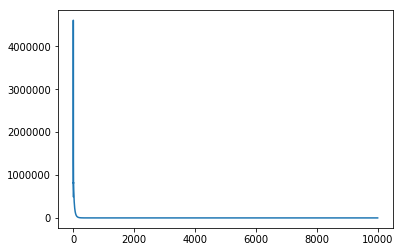

In [ ]:
max_iter = 10000
theta0 = 3
theta1 = 10
theta2 = -0.1
theta3 = 0
theta4 = 0
alpha = 0.0001 #Coeficiente de aprendizaje
J = np.zeros(max_iter)
save = [[theta0, theta1, theta2, theta3, theta4]]
lambda_reg = 10000

x0 = 1
x1 = x_obj
x2 = x_obj**2
x3 = x_obj**3
x4 = x_obj**4

for i in range(max_iter):
    dJ0 = 0
    dJ1 = 0
    dJ2 = 0
    dJ3 = 0
    dJ4 = 0
    for j in range(m):
        h = theta0*x0 + theta1*x1[j] + theta2*x2[j] + theta3*x3[j] + theta4*x4[j]
        reg = (lambda_reg/(2*m))*(np.sum(np.array([theta1, theta2, theta3, theta4])**2))
        dJ0 = dJ0 + (1/m)*(h - y_obj[j])
        dJ1 = dJ1 + (1/m)*(h - y_obj[j])*x1[j] + (lambda_reg/m)*theta1
        dJ2 = dJ1 + (1/m)*(h - y_obj[j])*x2[j] + (lambda_reg/m)*theta2
        dJ3 = dJ1 + (1/m)*(h - y_obj[j])*x3[j] + (lambda_reg/m)*theta3
        dJ4 = dJ1 + (1/m)*(h - y_obj[j])*x4[j] + (1000000/m)*theta4
        J[i]= J[i] + (1/(2*m))*(y_obj[j] - h)**2 + reg 
    theta0 = theta0 - alpha*dJ0
    theta1 = theta1 - alpha*dJ1
    theta2 = theta2 - alpha*dJ2
    theta3 = theta3 - alpha*dJ3
    theta4 = theta4 - alpha*dJ4
    save.append([theta0, theta1, theta2, theta3, theta4])

print(theta0_obj, theta1_obj, theta2_obj)     
print(theta0, theta1, theta2, theta3, theta4)  
print(J[-1], dJ0, dJ1, dJ2, dJ3, dJ4)
plt.plot(range(max_iter), J)

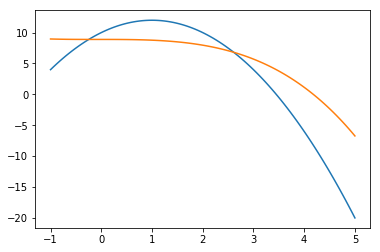

In [ ]:
plt.plot(x1, theta0_obj + theta1_obj*x1 + theta2_obj*x2)
plt.plot(x1, theta0 + theta1*x1 + theta2*x2 + theta3*x3 + theta4*x4)
